# Surface Code Threshold under Circuit-Level Noise
### Numerical simulation with Stim + Minimum-Weight Perfect Matching (PyMatching)

**Goal.** Estimate the error-correction threshold of the rotated surface code in a *memory experiment*: encode a logical qubit, run $d$ rounds of stabilizer measurement under noise, decode the syndrome history, and check whether the logical qubit survived.

**Pipeline**
1. Generate the noisy syndrome-extraction circuit (Stim).
2. Convert it into a *detector error model* (DEM): which physical faults flip which detectors / the logical observable.
3. Build a matching graph from the DEM and decode sampled syndromes with MWPM (PyMatching).
4. Sweep code distance $d$ and physical error rate $p$, and locate the threshold $p_{th}$ where the curves cross.
5. Below threshold, measure the error-suppression factor $\Lambda = \varepsilon_d / \varepsilon_{d+2}$.

**Noise model (circuit-level, uniform depolarizing, strength $p$):** two-qubit depolarizing after every CNOT, single-qubit depolarizing on data qubits at the start of each round, bit-flips after resets and before measurements.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import stim
import pymatching

print("stim", stim.__version__, "| pymatching", pymatching.__version__)
rng_seed = 2026

stim 1.16.0 | pymatching 2.4.0


## 1. Building the noisy circuit

Stim ships a generator for the rotated surface code memory experiment. `rotated_memory_z` prepares logical $|0\rangle_L$, measures stabilizers for `rounds` rounds, then measures all data qubits in the Z basis. The logical observable is the parity of a row of data qubits.

In [2]:
def surface_code_circuit(d: int, p: float, rounds: int | None = None) -> stim.Circuit:
    """Rotated surface code Z-memory experiment with uniform circuit-level noise p."""
    return stim.Circuit.generated(
        "surface_code:rotated_memory_z",
        distance=d,
        rounds=rounds if rounds is not None else d,
        after_clifford_depolarization=p,
        before_round_data_depolarization=p,
        after_reset_flip_probability=p,
        before_measure_flip_probability=p,
    )

c3 = surface_code_circuit(d=3, p=1e-3)
used = {t.value for inst in c3.flattened() for t in inst.targets_copy() if t.is_qubit_target}
print(f"physical qubits used: {len(used)}  (9 data + 8 measure qubits; Stim indexes them sparsely up to {c3.num_qubits - 1})")
print(f"detectors:   {c3.num_detectors}")
print(f"observables: {c3.num_observables}")

physical qubits used: 17  (9 data + 8 measure qubits; Stim indexes them sparsely up to 25)
detectors:   24
observables: 1


### Sanity check: is the *circuit-level* distance really $d$?

Hook errors in a badly scheduled syndrome circuit can reduce the effective distance. Stim can search for the smallest set of graph-like faults that flips the logical observable without triggering any detector.

In [3]:
for d in [3, 5, 7]:
    c = surface_code_circuit(d, p=1e-3)
    w = len(c.shortest_graphlike_error())
    print(f"d = {d}: minimum-weight undetectable logical error = {w} faults")

d = 3: minimum-weight undetectable logical error = 3 faults
d = 5: minimum-weight undetectable logical error = 5 faults
d = 7: minimum-weight undetectable logical error = 7 faults


## 2. From circuit to matching graph

A **detector** is a parity of measurement outcomes that is deterministic without noise (typically: a stabilizer outcome compared with the same stabilizer in the previous round). Each fault mechanism flips a small set of detectors. For the surface code with depolarizing noise, after decomposing $Y$-type errors, every fault flips at most 2 detectors, so the DEM is a **graph**: detectors are nodes, faults are weighted edges ($w = \log\frac{1-p_e}{p_e}$). Decoding = finding the most likely set of edges explaining the observed defects, i.e. a minimum-weight perfect matching.

In [4]:
dem = c3.detector_error_model(decompose_errors=True)
matcher = pymatching.Matching.from_detector_error_model(dem)
print(f"DEM fault mechanisms: {dem.num_errors}")
print(f"matching graph: {matcher.num_detectors} nodes, {matcher.num_edges} edges")
print("\nfirst lines of the DEM:")
print("\n".join(str(dem).splitlines()[:6]))

DEM fault mechanisms: 286
matching graph: 24 nodes, 78 edges

first lines of the DEM:
error(0.001931182734310662227) D0
error(0.001931182734310662227) D0 D1
error(0.002263671931417261113) D0 D8
error(0.001931182734310662227) D1 D2
error(0.002396454743836353742) D1 D5
error(0.0001333866998761607556) D1 D5 ^ D4


## 3. Sample, decode, count logical failures

For each shot Stim returns the detector outcomes and the true flip of the logical observable. The decoder only sees the detectors and predicts the observable flip; a **logical error** is a mismatch.

Shots are drawn in batches until either `max_errors` failures or `max_shots` shots are collected, so the relative statistical error is controlled at every point.

In [5]:
def logical_error_rate(d, p, rounds=None, max_shots=2_000_000, max_errors=300, batch=50_000, seed=rng_seed):
    circuit = surface_code_circuit(d, p, rounds)
    dem = circuit.detector_error_model(decompose_errors=True)
    matcher = pymatching.Matching.from_detector_error_model(dem)
    sampler = circuit.compile_detector_sampler(seed=seed)
    shots = errors = 0
    while shots < max_shots and errors < max_errors:
        n = min(batch, max_shots - shots)
        det, obs = sampler.sample(n, separate_observables=True)
        pred = matcher.decode_batch(det)
        errors += int(np.sum(np.any(pred != obs, axis=1)))
        shots += n
    return errors, shots

def per_round(P, r):
    """Convert a total logical error probability over r rounds into a per-round rate."""
    return 0.5 * (1 - (1 - 2 * P) ** (1 / r))

e, n = logical_error_rate(d=3, p=5e-3)
print(f"d=3, p=0.5%: {e} logical errors in {n} shots -> P_L = {e/n:.4f}")

d=3, p=0.5%: 840 logical errors in 50000 shots -> P_L = 0.0168


## 4. Threshold sweep

We use $d$ rounds for a distance-$d$ code (so time-like and space-like error chains are both relevant) and report the **logical error rate per round** $\varepsilon_d$, which makes different $d$ directly comparable. Error bars: binomial standard error, propagated to the per-round rate.

In [6]:
distances = [3, 5, 7]
ps = np.geomspace(2e-3, 1.4e-2, 9)
results = {}
t0 = time.time()
for d in distances:
    for p in ps:
        e, n = logical_error_rate(d, p)
        results[(d, p)] = (e, n)
        print(f"d={d}  p={p:.4f}  errors={e:4d}  shots={n:>9,d}  P_L={e/n:.2e}")
print(f"\ntotal time: {time.time()-t0:.0f} s")

d=3  p=0.0020  errors= 332  shots=  100,000  P_L=3.32e-03
d=3  p=0.0026  errors= 459  shots=  100,000  P_L=4.59e-03
d=3  p=0.0033  errors= 386  shots=   50,000  P_L=7.72e-03


d=3  p=0.0041  errors= 637  shots=   50,000  P_L=1.27e-02
d=3  p=0.0053  errors= 851  shots=   50,000  P_L=1.70e-02
d=3  p=0.0067  errors=1511  shots=   50,000  P_L=3.02e-02


d=3  p=0.0086  errors=2274  shots=   50,000  P_L=4.55e-02


d=3  p=0.0110  errors=3501  shots=   50,000  P_L=7.00e-02


d=3  p=0.0140  errors=5277  shots=   50,000  P_L=1.06e-01


d=5  p=0.0020  errors= 351  shots=  350,000  P_L=1.00e-03


... (12 outputs left out)

d=7  p=0.0067  errors=1421  shots=   50,000  P_L=2.84e-02


d=7  p=0.0086  errors=3404  shots=   50,000  P_L=6.81e-02


d=7  p=0.0110  errors=6698  shots=   50,000  P_L=1.34e-01


d=7  p=0.0140  errors=12053  shots=   50,000  P_L=2.41e-01

total time: 27 s


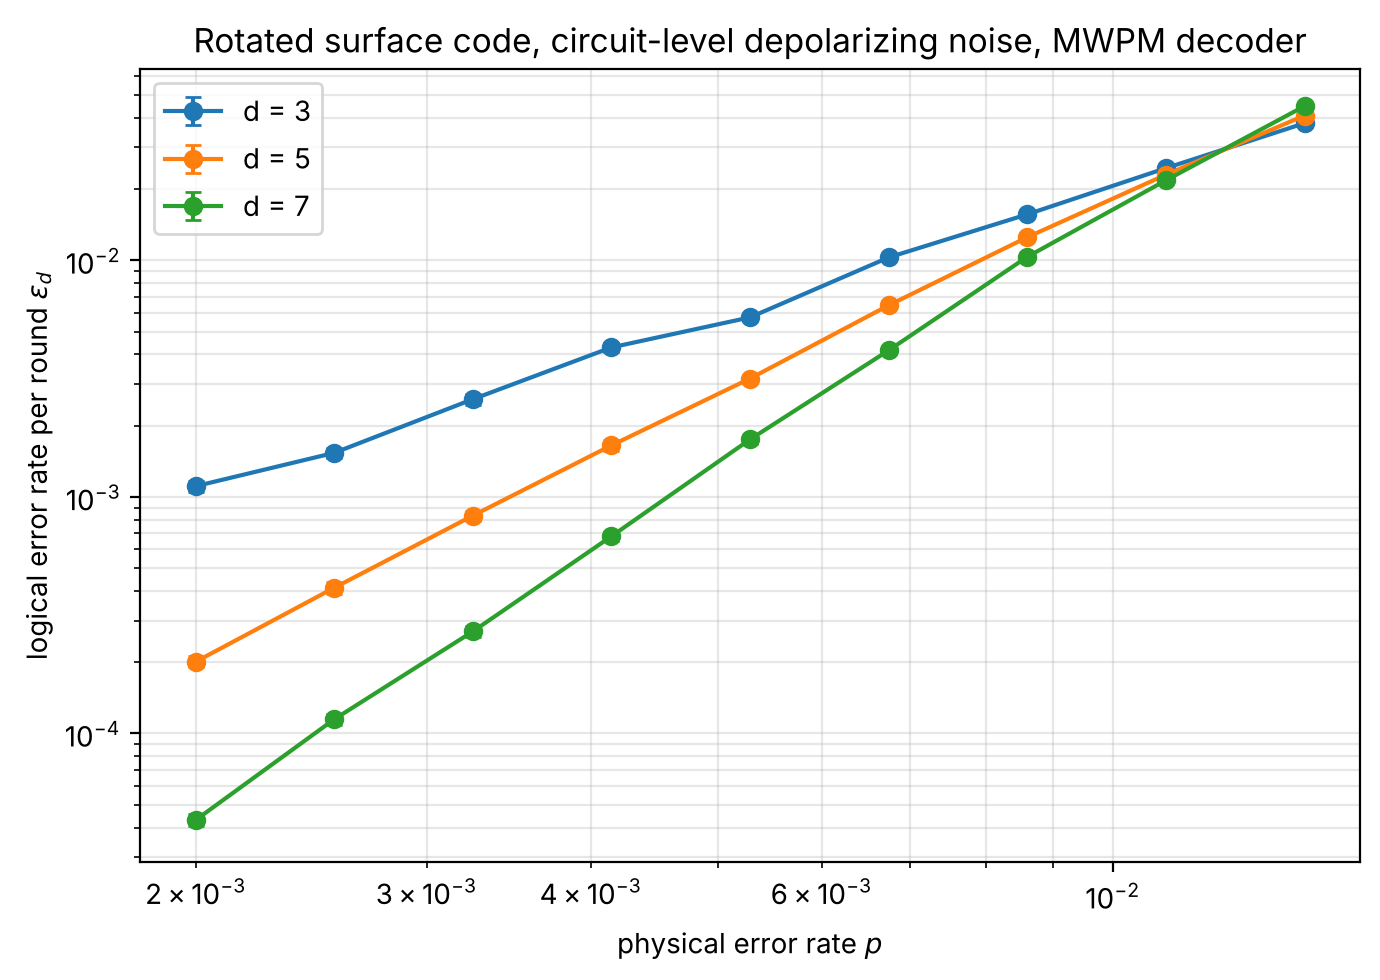

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
curves = {}
for d in distances:
    P = np.array([results[(d, p)][0] / results[(d, p)][1] for p in ps])
    N = np.array([results[(d, p)][1] for p in ps])
    sig = np.sqrt(P * (1 - P) / N)
    eps = per_round(P, d)
    lo = eps - per_round(np.clip(P - sig, 0, None), d)
    hi = per_round(P + sig, d) - eps
    curves[d] = eps
    ax.errorbar(ps, eps, yerr=[lo, hi], marker="o", capsize=3, label=f"d = {d}")

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("physical error rate $p$")
ax.set_ylabel(r"logical error rate per round $\varepsilon_d$")
ax.set_title("Rotated surface code, circuit-level depolarizing noise, MWPM decoder")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("threshold_plot.png", dpi=150)
plt.show()

### Threshold estimate

The threshold is where the curves cross: below it a larger code is better, above it worse. We estimate it from the crossing of the $d=3$ and $d=7$ curves (interpolating $\log\varepsilon$ linearly in $\log p$).

In [8]:
def crossing(x, y1, y2):
    lx, f = np.log(x), np.log(y1) - np.log(y2)
    i = np.where(np.sign(f[:-1]) != np.sign(f[1:]))[0]
    if len(i) == 0:
        return None
    i = i[0]
    return float(np.exp(lx[i] - f[i] * (lx[i+1] - lx[i]) / (f[i+1] - f[i])))

for a, b in [(3, 5), (5, 7), (3, 7)]:
    x = crossing(ps, curves[a], curves[b])
    print(f"crossing d={a} / d={b}: p ≈ {x:.4%}" if x else f"no crossing d={a}/{b} in range")

crossing d=3 / d=5: p ≈ 1.2279%
crossing d=5 / d=7: p ≈ 1.2021%
crossing d=3 / d=7: p ≈ 1.2146%


## 5. Below threshold: error-suppression factor $\Lambda$

Below threshold, $\varepsilon_d \approx A\,(p/p_{th})^{(d+1)/2}$, so every increase $d \to d+2$ divides the logical error rate by a constant factor $\Lambda$. This is the figure of merit used in recent hardware experiments (e.g. Google's below-threshold surface-code demonstrations).

In [9]:
p_low = ps[0]
print(f"at p = {p_low:.3%}:")
for a, b in [(3, 5), (5, 7)]:
    lam = curves[a][0] / curves[b][0]
    print(f"  Lambda_{a}->{b} = eps_{a} / eps_{b} = {lam:.2f}")

# Scaling check: slope of log(eps) vs log(p) below threshold should be ~ (d+1)/2
print("\nlow-p slope of log(eps_d) vs log(p)  (theory: (d+1)/2)")
for d in distances:
    k = 3
    slope = np.polyfit(np.log(ps[:k]), np.log(curves[d][:k]), 1)[0]
    print(f"  d={d}: fitted slope {slope:.2f}   theory {(d+1)/2:.1f}")

at p = 0.200%:
  Lambda_3->5 = eps_3 / eps_5 = 5.53
  Lambda_5->7 = eps_5 / eps_7 = 4.67

low-p slope of log(eps_d) vs log(p)  (theory: (d+1)/2)
  d=3: fitted slope 1.74   theory 2.0
  d=5: fitted slope 2.92   theory 3.0
  d=7: fitted slope 3.77   theory 4.0


## 6. Takeaways and next steps

- With uniform circuit-level depolarizing noise (no idle errors) and an MWPM decoder, the curves cross at **$p_{th} \approx 1.2\%$** (per-round logical error rate). This is in the ~1% range usually quoted for this kind of noise model; adding idle errors or a more realistic hardware model (e.g. SI1000) pushes it down to ~0.5–0.7%.
- Below threshold the logical error rate is suppressed exponentially with distance: at $p = 0.2\%$, $\Lambda \approx 5$, and the fitted slopes approach the expected $(d+1)/2$ as $p \to 0$.
- The circuit-level distance equals $d$, confirming the default CNOT schedule has no distance-reducing hook errors.

**Possible extensions**
1. **Noise models:** compare code-capacity (data errors only, threshold ~10%) and phenomenological noise to isolate the cost of noisy syndrome extraction; add biased (Z-dominated) noise.
2. **Decoders:** correlated matching (using X–Z correlations from Y errors), Union-Find, or belief-propagation + OSD; compare accuracy vs. runtime.
3. **Machine-learning decoder (QML bridge):** train a neural network (CNN/transformer over the syndrome history) on Stim samples and benchmark it against MWPM, the approach behind recent neural decoders such as Google DeepMind's AlphaQubit.
4. **Other codes:** repetition code under the same pipeline, or qLDPC codes (e.g. bivariate bicycle codes) with BP-OSD.